# 정책 자연실험: 토지거래허가구역·규제지역 지정/해제가 아파트 가격에 미친 영향

## 질문

같은 시기, 비슷한 지역인데 **정책 적용 여부만 갈린 아파트**를 비교하면 정책 효과를 추정할 수 있다.
가격 예측 모델(상관관계)과 달리, 여기서는 이중차분(DiD)과 이벤트 스터디로 **정책 전후 차이의 차이**를 본다.

| 사건 | 처치군 | 대조군 | 분석 기간 |
|---|---|---|---|
| **A. 2025-02-13 잠실·삼성·청담·대치 토허 해제** | 해제된 아파트 (재건축 14곳 제외) | 강남·서초·송파에서 그때까지 지정된 적 없는 아파트 | 2024-08-17 ~ 2025-03-23 (3/24 재지정 전날) |
| **B. 2025-03-24 강남3구·용산 아파트 전체 토허 지정** | 새로 지정된 4개 구 아파트 (잠삼대청·압구정 제외) | 나머지 21개 구에서 지정된 적 없는 아파트 | 2024-09-25 ~ 2025-06-27 (6.27 대책 전날) |
| **C. 2023-01-05 서울 21개 구 규제지역 해제** | 해제된 21개 구 | 유지된 강남3구·용산 | 2022-07-09 ~ 2023-06-30 (참고용) |

### 방법

- **Outcome:** 거래 단위 `log(평당가)`. 직거래는 제외한다(시세와 다른 거래가 섞임).
- **모형:** `log평당가 = 단지 FE + 기간 FE + Σ βₖ·처치×기간ₖ + 면적·층 + ε`
  - 기간은 사건일 기준 30일 단위(k=-1이 기준), 표준오차는 단지 단위 군집.
  - 단지 FE로 단지 자체의 가격 수준 차이를, 기간 FE로 서울 전체 시장 흐름을 제거한다.
- **식별 가정:** 사건이 없었다면 처치군과 대조군 가격이 평행하게 움직였을 것 → 사건 전 βₖ가 0 근처인지 확인한다.
- 회귀는 `numpy`로 직접 구현했고, 효과를 심은 가상 데이터로 추정치가 복원되는지 검증한다.

### 주의

- 처치군·대조군 사이 **파급 효과**(규제 피해 대조군으로 수요 이동)가 있으면 효과가 과대 추정된다.
- A는 해제 발표 전 **기대 효과**가 있었을 수 있다(2025-01 서울시장 해제 검토 발언).
- C는 같은 시기 특례보금자리론(2023-01-30, 9억 이하)이 저가 구에 더 유리해 효과가 섞인다 → 참고용.

In [1]:
# ============================================================
# 경로·데이터
# ============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


def find_project_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "data").exists():
            return path
    raise FileNotFoundError("프로젝트 루트에서 data 폴더를 찾을 수 없습니다.")


PROJECT_DIR = find_project_root()
PROCESSED_DIR = PROJECT_DIR / "data" / "v2_5year_seoul" / "processed"

trades = pd.read_parquet(
    PROCESSED_DIR / "df_fe_base.parquet",
    columns=["transaction_id", "계약일자", "시군구명", "법정동", "단지명", "단지일련번호",
             "평당가", "전용면적", "층", "거래유형"],
)
policy = pd.read_parquet(
    PROCESSED_DIR / "policy_trade_v2.parquet",
    columns=["transaction_id", "토허_단지지정", "토허_동노출", "투기과열지구_계약일"],
)
trades = trades.merge(policy, on="transaction_id")
trades = trades[trades["거래유형"].ne("직거래")].copy()
trades["y"] = np.log(trades["평당가"].astype(float))
trades["log면적"] = np.log(trades["전용면적"].astype(float))
trades["층"] = pd.to_numeric(trades["층"], errors="coerce").clip(lower=-2, upper=60)
trades = trades.dropna(subset=["y", "log면적", "층"])

GANGNAM3 = ["강남구", "서초구", "송파구"]
CORE4 = GANGNAM3 + ["용산구"]
JSCD = ["잠실동", "삼성동", "청담동", "대치동"]

print("직거래 제외 거래:", trades.shape)

직거래 제외 거래: (222379, 15)


## 1. 회귀 함수 (단지 FE + 기간 FE, 단지 군집 표준오차)

In [2]:
# ============================================================
# 단지 FE는 단지 내 평균을 빼서 흡수하고(within 변환), 기간 FE는 더미로 넣는다 (FWL 정리로 동일한 추정).
# 표준오차: 단지 군집 sandwich, 소표본 보정 G/(G-1)·(N-1)/(N-K)
# ============================================================

def twfe(df, effect_cols, controls=("log면적", "층"), unit="단지일련번호", period="k"):
    d = df.copy()
    d = d[d.groupby(unit)[unit].transform("size") > 1]  # 거래 1건뿐인 단지는 정보가 없다

    period_dummies = pd.get_dummies(d[period], prefix="p", drop_first=True, dtype=float)
    X = pd.concat([d[list(effect_cols) + list(controls)].astype(float), period_dummies], axis=1)
    y = d["y"].astype(float)

    group = d[unit].to_numpy()
    Xd = X - X.groupby(group).transform("mean")
    yd = y - y.groupby(group).transform("mean")

    Xv, yv = Xd.to_numpy(), yd.to_numpy()
    beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    resid = yv - Xv @ beta

    bread = np.linalg.pinv(Xv.T @ Xv)
    scores = pd.DataFrame(Xv * resid[:, None]).groupby(group).sum().to_numpy()
    n, k, g = len(yv), Xv.shape[1], len(np.unique(group))
    vcov = bread @ (scores.T @ scores) @ bread * (g / (g - 1)) * ((n - 1) / (n - k))

    se = np.sqrt(np.diag(vcov))
    out = pd.DataFrame({"coef": beta, "se": se}, index=X.columns)
    tcrit = stats.t.ppf(0.975, g - 1)
    out["lo"], out["hi"] = out["coef"] - tcrit * out["se"], out["coef"] + tcrit * out["se"]
    out["p"] = 2 * stats.t.sf(np.abs(out["coef"] / out["se"]), g - 1)
    return out, vcov, X.columns.tolist(), {"N": n, "단지": g}


def wald_p(vcov, names, out, cols):
    # 사건 전 계수들이 모두 0인지 (평행 추세 검정)
    idx = [names.index(c) for c in cols]
    b = out.loc[cols, "coef"].to_numpy()
    v = vcov[np.ix_(idx, idx)]
    stat = float(b @ np.linalg.pinv(v) @ b)
    return stats.chi2.sf(stat, len(cols))

## 2. 사건별 표본 구성

In [3]:
# ============================================================
# 사건 정의
# - k: 사건일 기준 30일 단위 기간 (사건일 = k 0의 시작)
# ============================================================

RETAINED_14 = {
    "대치동": r"^(은마|한보미도맨션[12]|개포우성[12]|선경[12]차.*|쌍용대치.*|대치우성.*)$",
    "청담동": r"^(현대아파트\(75-1\)|진흥아파트)$",
    "삼성동": r"^진흥아파트$",
    "잠실동": r"^(주공아파트 5단지|우성아파트|우성4차|아시아선수촌아파트)$",
}


def retained(row):
    pattern = RETAINED_14.get(row["법정동"])
    return bool(pattern and isinstance(row["단지명"], str) and re.match(pattern, row["단지명"]))


def ever_designated(df, start, end):
    # 기간 중 한 번이라도 단지 지정 또는 동 노출이 있었던 단지
    w = df[df["계약일자"].between(start, end)]
    flag = (w["토허_단지지정"].eq(1) | w["토허_동노출"].eq(1)).groupby(w["단지일련번호"]).max()
    return set(flag[flag].index)


def make_sample(event, start, end, treated_mask, control_mask):
    d = trades[trades["계약일자"].between(start, end) & (treated_mask | control_mask)].copy()
    d["treated"] = treated_mask.loc[d.index].astype(int)
    d["k"] = ((d["계약일자"] - pd.Timestamp(event)).dt.days // 30).astype(int)
    return d


EVENTS = {}

# A. 2025-02-13 잠삼대청 해제
ev = "2025-02-13"
start, end = pd.Timestamp(ev) - pd.Timedelta(days=180), pd.Timestamp("2025-03-23")
in_jscd = trades["시군구명"].isin(["강남구", "송파구"]) & trades["법정동"].isin(JSCD)
is_retained = pd.Series(False, index=trades.index, dtype=bool)
is_retained.loc[in_jscd] = trades.loc[in_jscd].apply(retained, axis=1).astype(bool)
designated_before = ever_designated(trades[~in_jscd], start, end)
treated_a = in_jscd & ~is_retained
control_a = (trades["시군구명"].isin(GANGNAM3) & ~in_jscd
             & ~trades["단지일련번호"].isin(designated_before))
EVENTS["A. 잠삼대청 토허 해제 (2025-02-13)"] = make_sample(ev, start, end, treated_a, control_a)

# B. 2025-03-24 강남3구·용산 전체 지정
ev = "2025-03-24"
start, end = pd.Timestamp(ev) - pd.Timedelta(days=180), pd.Timestamp("2025-06-27")
already = ever_designated(trades, start, pd.Timestamp(ev) - pd.Timedelta(days=1))
treated_b = (trades["시군구명"].isin(CORE4) & ~in_jscd & ~trades["법정동"].eq("압구정동")
             & ~trades["단지일련번호"].isin(already))
control_b = (~trades["시군구명"].isin(CORE4)
             & ~trades["단지일련번호"].isin(ever_designated(trades, start, end)))
EVENTS["B. 강남3구·용산 토허 지정 (2025-03-24)"] = make_sample(ev, start, end, treated_b, control_b)

# C. 2023-01-05 규제지역 해제
ev = "2023-01-05"
start, end = pd.Timestamp(ev) - pd.Timedelta(days=180), pd.Timestamp("2023-06-30")
treated_c = ~trades["시군구명"].isin(CORE4)
control_c = trades["시군구명"].isin(CORE4)
EVENTS["C. 21개 구 규제지역 해제 (2023-01-05)"] = make_sample(ev, start, end, treated_c, control_c)

summary = pd.DataFrame({
    name: {
        "처치 단지": d.loc[d["treated"].eq(1), "단지일련번호"].nunique(),
        "대조 단지": d.loc[d["treated"].eq(0), "단지일련번호"].nunique(),
        "처치 거래(전/후)": f"{(d['treated'].eq(1) & d['k'].lt(0)).sum()} / {(d['treated'].eq(1) & d['k'].ge(0)).sum()}",
        "대조 거래(전/후)": f"{(d['treated'].eq(0) & d['k'].lt(0)).sum()} / {(d['treated'].eq(0) & d['k'].ge(0)).sum()}",
        "k 범위": f"{d['k'].min()} ~ {d['k'].max()}",
    }
    for name, d in EVENTS.items()
}).T
display(summary)

,처치 단지,대조 단지,처치 거래(전/후),대조 거래(전/후),k 범위
A. 잠삼대청 토허 해제 (2025-02-13),124,693,465 / 557,3376 / 2919,-6 ~ 1
B. 강남3구·용산 토허 지정 (2025-03-24),824,3645,5794 / 2012,18892 / 19603,-6 ~ 3
C. 21개 구 규제지역 해제 (2023-01-05),2871,726,2542 / 12396,678 / 3490,-6 ~ 5


## 3. 구현 검증: 효과를 심은 가상 데이터

사건 A 표본에서 처치군의 사건 후 거래 가격에 **+5%**를 더한 뒤 다시 추정한다.
추정 DiD가 원래 값보다 정확히 log(1.05)만큼 커져야 한다.

In [4]:
# ============================================================
# 가상 효과 복원 + 가짜 사건(1년 전) 점검
# ============================================================

def did(d):
    d = d.assign(post=(d["k"] >= 0).astype(int))
    d["처치×사후"] = d["treated"] * d["post"]
    out, *_ = twfe(d, ["처치×사후"])
    return out.loc["처치×사후"]


name_a = list(EVENTS)[0]
base_a = EVENTS[name_a]
original = did(base_a)["coef"]

injected = base_a.copy()
mask = injected["treated"].eq(1) & injected["k"].ge(0)
injected.loc[mask, "y"] += np.log(1.05)
recovered = did(injected)["coef"]

print(f"원래 DiD {original:.4f} → 효과 주입 후 {recovered:.4f} (차이 {recovered - original:.4f}, 기대 {np.log(1.05):.4f})")
assert abs((recovered - original) - np.log(1.05)) < 1e-8

print("✅ 회귀 구현이 심은 효과를 정확히 복원함")

원래 DiD 0.0300 → 효과 주입 후 0.0788 (차이 0.0488, 기대 0.0488)
✅ 회귀 구현이 심은 효과를 정확히 복원함


## 4. 결과: 이벤트 스터디와 DiD

In [5]:
# ============================================================
# 사건별 추정
# - 이벤트 스터디: 처치 × k (k=-1 기준, k ≤ -6은 -6으로 묶음)
# - DiD: 처치 × 사후(k ≥ 0)
# ============================================================

results, curves = [], {}

for name, d in EVENTS.items():
    d = d.copy()
    d["k_bin"] = d["k"].clip(lower=-6)
    ks = sorted(k for k in d["k_bin"].unique() if k != -1)
    effect_cols = []
    for k in ks:
        col = f"treat_k{k}"
        d[col] = (d["treated"].eq(1) & d["k_bin"].eq(k)).astype(int)
        effect_cols.append(col)
    out, vcov, names, info = twfe(d.assign(k=d["k_bin"]), effect_cols)

    curve = out.loc[effect_cols, ["coef", "lo", "hi"]].copy()
    curve.index = ks
    curve.loc[-1] = [0.0, 0.0, 0.0]
    curves[name] = curve.sort_index()

    pre_cols = [f"treat_k{k}" for k in ks if k < -1]
    est = did(d)
    results.append({
        "사건": name,
        "DiD(%)": (np.exp(est["coef"]) - 1) * 100,
        "95% CI(%)": f"{(np.exp(est['lo']) - 1) * 100:.1f} ~ {(np.exp(est['hi']) - 1) * 100:.1f}",
        "p": est["p"],
        "사전추세 검정 p": wald_p(vcov, names, out, pre_cols),
        "N": info["N"], "단지": info["단지"],
    })

results = pd.DataFrame(results).set_index("사건")
display(results.round(3))

,DiD(%),95% CI(%),p,사전추세 검정 p,N,단지
사건,,,,,,
A. 잠삼대청 토허 해제 (2025-02-13),3.044,2.0 ~ 4.1,0.000,0.623,7051,551
B. 강남3구·용산 토허 지정 (2025-03-24),3.218,2.4 ~ 4.0,0.000,0.000,45016,3184
C. 21개 구 규제지역 해제 (2023-01-05),-2.323,-3.7 ~ -1.0,0.001,0.153,17670,2161


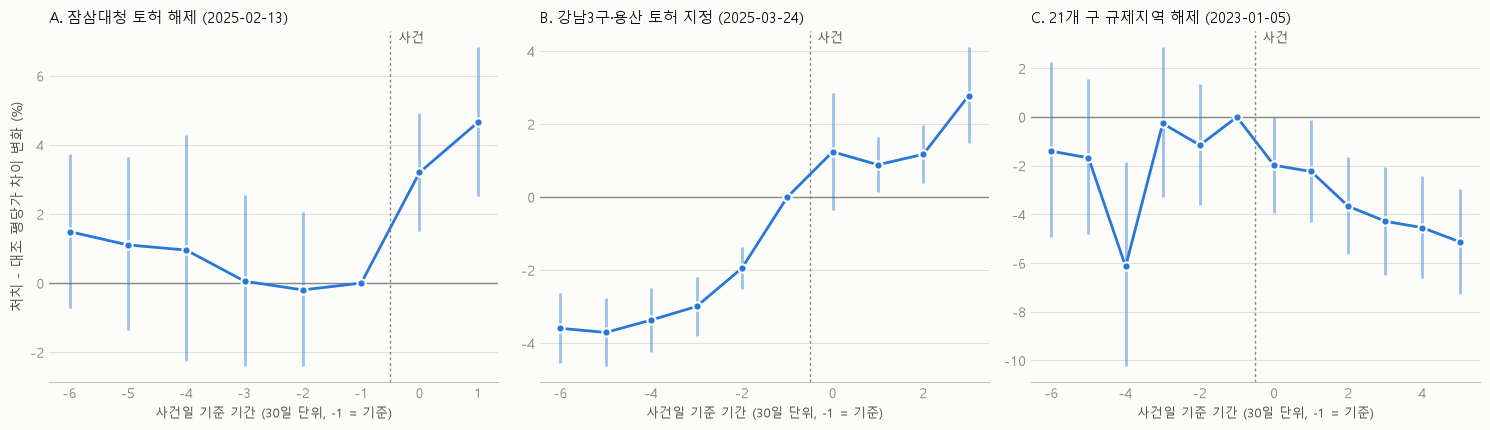

A. 잠삼대청 토허 해제 (2025-02-13)             B. 강남3구·용산 토허 지정 (2025-03-24)        \
                         coef    lo    hi                          coef    lo   
-6                       1.49 -0.71  3.74                         -3.59 -4.56   
-5                       1.11 -1.37  3.65                         -3.71 -4.63   
-4                       0.96 -2.27  4.29                         -3.37 -4.25   
-3                       0.06 -2.39  2.56                         -2.99 -3.80   
-2                      -0.20 -2.41  2.06                         -1.95 -2.53   
-1                       0.00  0.00  0.00                          0.00  0.00   
 0                       3.20  1.50  4.93                          1.24 -0.35   
 1                       4.65  2.52  6.83                          0.88  0.13   
 2                        NaN   NaN   NaN                          1.17  0.39   
 3                        NaN   NaN   NaN                          2.78  1.47   
 4                        NaN   NaN   NaN                           NaN   NaN   
 5                        NaN   NaN   NaN                           NaN   NaN   

         C. 21개 구 규제지역 해제 (2023-01-05)               
      hi                          coef     lo    hi  
-6 -2.62                         -1.40  -4.93  2.26  
-5 -2.77                         -1.68  -4.81  1.56  
-4 -2.48                         -6.14 -10.24 -1.85  
-3 -2.19                         -0.26  -3.30  2.87  
-2 -1.36                         -1.15  -3.62  1.37  
-1  0.00                          0.00   0.00  0.00  
 0  2.86                         -1.98  -3.93  0.01  
 1  1.64                         -2.24  -4.32 -0.11  
 2  1.97                         -3.66  -5.63 -1.65  
 3  4.10                         -4.28  -6.47 -2.05  
 4   NaN                         -4.55  -6.62 -2.43  
 5   NaN                         -5.12  -7.26 -2.94

In [6]:
# ============================================================
# 이벤트 스터디 그림 (사건별 패널)
# - 점: 처치군과 대조군의 가격 차이 변화(%), 막대: 95% 신뢰구간, k=-1 기준
# ============================================================

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE = "#2a78d6"

fig, axes = plt.subplots(1, len(curves), figsize=(15, 4.4), facecolor=SURFACE, sharey=False)
for ax, (name, c) in zip(axes, curves.items()):
    ax.set_facecolor(SURFACE)
    pct = (np.exp(c) - 1) * 100
    ax.axhline(0, color=MUTED, lw=1)
    ax.axvline(-0.5, color=MUTED, lw=1, ls=(0, (2, 2)))
    ax.vlines(pct.index, pct["lo"], pct["hi"], color=BLUE, lw=2, alpha=0.45)
    ax.plot(pct.index, pct["coef"], color=BLUE, lw=2, marker="o", ms=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
    ax.set_title(name, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("사건일 기준 기간 (30일 단위, -1 = 기준)", color=INK_2, fontsize=9)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.text(-0.45, ax.get_ylim()[1], " 사건", color=INK_2, fontsize=9, va="top")

axes[0].set_ylabel("처치 - 대조 평당가 차이 변화 (%)", color=INK_2)
plt.tight_layout()
plt.show()

display(pd.concat({n: ((np.exp(c) - 1) * 100).round(2) for n, c in curves.items()}, axis=1))

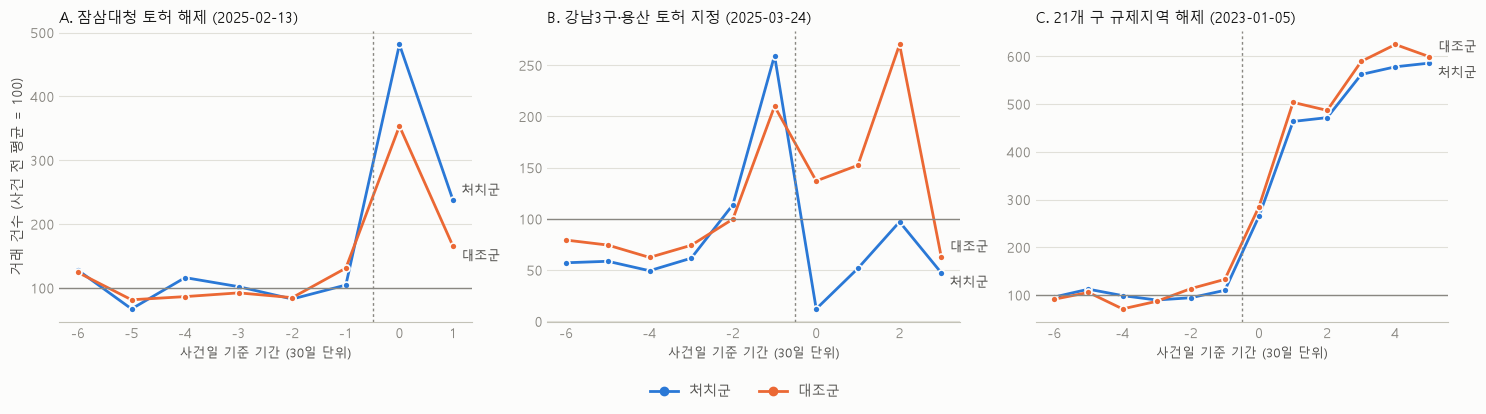

In [7]:
# ============================================================
# 거래량 변화: 30일 기간별 거래 건수, 사건 전 평균 = 100
# ============================================================

ORANGE = "#eb6834"
fig, axes = plt.subplots(1, len(EVENTS), figsize=(15, 4.0), facecolor=SURFACE)
for ax, (name, d) in zip(axes, EVENTS.items()):
    ax.set_facecolor(SURFACE)
    cnt = d.groupby(["k", "treated"]).size().unstack(fill_value=0)
    cnt = cnt[cnt.index >= -6]
    idx = cnt / cnt[cnt.index < 0].mean() * 100
    last = idx.iloc[-1]
    for col, color, label in [(1, BLUE, "처치군"), (0, ORANGE, "대조군")]:
        ax.plot(idx.index, idx[col], color=color, lw=2, marker="o", ms=5,
                markeredgecolor=SURFACE, markeredgewidth=1.2)
        dy = 7 if last[col] >= last[1 - col] else -7
        ax.annotate(label, (idx.index[-1], last[col]), xytext=(6, dy), textcoords="offset points",
                    color=INK_2, fontsize=9, va="center")
    ax.axhline(100, color=MUTED, lw=1)
    ax.axvline(-0.5, color=MUTED, lw=1, ls=(0, (2, 2)))
    ax.set_title(name, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("사건일 기준 기간 (30일 단위)", color=INK_2, fontsize=9)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

axes[0].set_ylabel("거래 건수 (사건 전 평균 = 100)", color=INK_2)
fig.legend(handles=[Line2D([], [], color=BLUE, lw=2, marker="o", label="처치군"),
                    Line2D([], [], color=ORANGE, lw=2, marker="o", label="대조군")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04), labelcolor=INK_2)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 5. 강건성 점검

1. **가짜 사건(placebo):** 같은 처치·대조 단지로 1년 전 날짜를 사건일로 놓고 추정한다. 효과가 0 근처여야 한다.
2. **기대 효과 제외 (A):** 해제 검토 발언(2025-01-14) 이후~해제 전 거래를 빼고 추정한다.
3. **추세 보정 DiD:** 처치군 고유의 선형 추세를 넣어, 사건 전부터 벌어지던 차이를 걷어낸다.
4. **거래량:** 토허 지정은 거래 자체를 막는 규제라 거래량 변화를 따로 본다.

In [8]:
# ============================================================
# 1. 가짜 사건: 1년 전
# ============================================================

placebo_rows = []
specs = [
    (list(EVENTS)[0], "2025-02-13", treated_a, control_a, 180, 38),
    (list(EVENTS)[1], "2025-03-24", treated_b, control_b, 180, 95),
    (list(EVENTS)[2], "2023-01-05", treated_c, control_c, 180, 176),
]
for name, ev, tmask, cmask, pre_days, post_days in specs:
    fake = pd.Timestamp(ev) - pd.DateOffset(years=1)
    d = make_sample(fake, fake - pd.Timedelta(days=pre_days), fake + pd.Timedelta(days=post_days), tmask, cmask)
    est = did(d)
    placebo_rows.append({"사건": name, "가짜 사건일": fake.date(),
                         "DiD(%)": (np.exp(est["coef"]) - 1) * 100, "p": est["p"], "N": len(d)})
display(pd.DataFrame(placebo_rows).set_index("사건").round(3))

,가짜 사건일,DiD(%),p,N
사건,,,,
A. 잠삼대청 토허 해제 (2025-02-13),2024-02-13,-0.649,0.557,3062
B. 강남3구·용산 토허 지정 (2025-03-24),2024-03-24,0.800,0.004,27849
C. 21개 구 규제지역 해제 (2023-01-05),2022-01-05,-3.105,0.000,21473


In [9]:
# ============================================================
# 2. 기대 효과 제외 (사건 A): 2025-01-14 ~ 2025-02-12 거래 제외
# ============================================================

d = EVENTS[list(EVENTS)[0]]
trimmed = d[~d["계약일자"].between("2025-01-14", "2025-02-12")]
est_full, est_trim = did(d), did(trimmed)
display(pd.DataFrame({
    "전체": [(np.exp(est_full["coef"]) - 1) * 100, est_full["p"], len(d)],
    "발언 이후~해제 전 제외": [(np.exp(est_trim["coef"]) - 1) * 100, est_trim["p"], len(trimmed)],
}, index=["DiD(%)", "p", "N"]).round(3))

,전체,발언 이후~해제 전 제외
DiD(%),3.044,2.921
p,0.000,0.000
N,7317.000,6499.000


In [10]:
# ============================================================
# 3. 추세 보정 DiD: 처치군 고유의 선형 추세(처치×k)를 함께 넣는다
#    사건 전부터 벌어지던 차이를 연장한 것보다 사건 후 얼마나 더(덜) 변했는지
# ============================================================

trend_rows = []
for name, d in EVENTS.items():
    d = d.assign(post=(d["k"] >= 0).astype(int))
    d["처치×사후"] = d["treated"] * d["post"]
    d["처치×추세"] = d["treated"] * d["k"]
    out, *_ = twfe(d, ["처치×사후", "처치×추세"])
    trend_rows.append({
        "사건": name,
        "추세 보정 DiD(%)": (np.exp(out.loc["처치×사후", "coef"]) - 1) * 100,
        "95% CI(%)": f"{(np.exp(out.loc['처치×사후', 'lo']) - 1) * 100:.1f} ~ {(np.exp(out.loc['처치×사후', 'hi']) - 1) * 100:.1f}",
        "p": out.loc["처치×사후", "p"],
        "처치군 추세(%/30일)": (np.exp(out.loc["처치×추세", "coef"]) - 1) * 100,
    })
trend = pd.DataFrame(trend_rows).set_index("사건")
display(trend.round(3))

,추세 보정 DiD(%),95% CI(%),p,처치군 추세(%/30일)
사건,,,,
A. 잠삼대청 토허 해제 (2025-02-13),3.877,2.2 ~ 5.6,0.000,-0.207
B. 강남3구·용산 토허 지정 (2025-03-24),-0.431,-1.2 ~ 0.4,0.283,0.820
C. 21개 구 규제지역 해제 (2023-01-05),0.469,-1.2 ~ 2.1,0.577,-0.485


In [11]:
# ============================================================
# 4. 거래량 DiD: log(30일 거래 건수)의 처치-대조 차이, 사건 전·후 평균 비교
#    (기간이 짧아 통계 검정 대신 크기만 본다)
# ============================================================

vol_rows = []
for name, d in EVENTS.items():
    cnt = d.groupby(["k", "treated"]).size().unstack(fill_value=0)
    cnt = cnt[cnt.index >= -6]
    gap = np.log(cnt[1]) - np.log(cnt[0])
    pre, post = gap[gap.index < 0].mean(), gap[gap.index >= 0].mean()
    vol_rows.append({
        "사건": name,
        "처치/대조 거래 비율 변화(%)": (np.exp(post - pre) - 1) * 100,
        "처치군 사후/사전 거래(%)": cnt.loc[cnt.index >= 0, 1].mean() / cnt.loc[cnt.index < 0, 1].mean() * 100,
        "대조군 사후/사전 거래(%)": cnt.loc[cnt.index >= 0, 0].mean() / cnt.loc[cnt.index < 0, 0].mean() * 100,
    })
volume = pd.DataFrame(vol_rows).set_index("사건")
display(volume.round(1))

,처치/대조 거래 비율 변화(%),처치군 사후/사전 거래(%),대조군 사후/사전 거래(%)
사건,,,
A. 잠삼대청 토허 해제 (2025-02-13),40.3,359.4,259.4
B. 강남3구·용산 토허 지정 (2025-03-24),-66.6,52.1,155.6
C. 21개 구 규제지역 해제 (2023-01-05),-7.0,487.6,514.7


In [12]:
# ============================================================
# 결과 저장 (웹 정책 카드·포트폴리오 보고용)
# ============================================================

curve_long = pd.concat(
    [((np.exp(c) - 1) * 100).assign(사건=n).rename_axis("k").reset_index() for n, c in curves.items()],
    ignore_index=True,
)
results = results.join(trend[["추세 보정 DiD(%)"]]).join(volume[["처치/대조 거래 비율 변화(%)"]])
results.reset_index().to_parquet(PROCESSED_DIR / "policy_event_study_v2.parquet", index=False)
curve_long.to_parquet(PROCESSED_DIR / "policy_event_study_curves_v2.parquet", index=False)
print(pd.read_parquet(PROCESSED_DIR / "policy_event_study_v2.parquet").shape,
      pd.read_parquet(PROCESSED_DIR / "policy_event_study_curves_v2.parquet").shape)

(3, 9) (30, 5)


## 결론

| 사건 | 가격 | 거래량 | 믿을 만한가 |
|---|---|---|---|
| **A. 잠삼대청 토허 해제** | 해제 후 약 5주 동안 강남3구 다른 아파트보다 **약 +3%** 더 상승 (추세 보정 시 약 +3.9%) | 처치/대조 거래 비율 **약 +40%** | **예.** 사전추세 평행(p≈0.62), 1년 전 가짜 사건 효과 없음(p≈0.56), 해제 기대 기간을 빼도 약 +2.9% |
| **B. 강남3구·용산 토허 지정** | 단순 DiD +3%는 지정 전부터 이어진 상대 상승 추세(약 +0.8%/30일). **추세 보정 시 약 −0.4%, 유의하지 않음** → 가격 하락 효과 없음 | 처치/대조 거래 비율 **약 −67%** → **거래 차단 효과 뚜렷** | 가격: 효과 없음 / 거래량: 예 |
| **C. 21개 구 규제지역 해제** | 단순 DiD −2%는 1년 전 가짜 사건에서도 비슷 → 추세 보정 시 약 +0.5%, 유의하지 않음 | 처치/대조 거래 비율 약 −7% (둘 다 비슷하게 회복) | 아니오 (동시 정책·시장 국면과 분리 불가) |

**포트폴리오 메시지**
- 토허 **해제**는 짧은 기간에도 가격을 밀어올렸다(약 3%). 반대로 **지정**은 가격을 낮추기보다 **거래를 묶었다** — 매물 잠김.
- 정책 효과를 주장하기 전에 사전추세·가짜 사건·기대 효과를 점검해야 하고, 이 점검에서 B·C의 가격 효과는 걸러졌다.
- 예측 모델(03 Policy Feature)이 정책 변수로 가격 방향을 잘 맞추지 못한 이유와도 연결된다:
  정책의 가격 효과는 작고 시장 국면과 섞여 있으며, 뚜렷한 효과는 거래량 쪽이다.

**한계**
- 거래가 성사된 아파트만 관측된다. 지정 후 거래가 급감하면 남은 거래의 구성이 달라질 수 있다(단지 FE로 일부만 통제).
- A의 사후 기간은 약 5주로 짧고, 이후 3/24 재지정으로 관측이 끊긴다.
- 대조군으로 수요가 옮겨 가는 파급 효과가 있으면 DiD가 과대 추정된다.